In [1]:
import sys, platform, time
import numpy as np
import pandas as pd
import sklearn, networkx as nx

print("Python", sys.version.split()[0], "|", platform.platform())
print("numpy", np.__version__, "| pandas", pd.__version__,
      "| sklearn", sklearn.__version__, "| networkx", nx.__version__)
try:
    import torch, torch_geometric
    print("torch", torch.__version__, "| PyG", torch_geometric.__version__,
          "| CUDA:", torch.cuda.is_available())
except ImportError:
    print("torch / PyG not installed")

Python 3.13.18 | Linux-6.6.159+-x86_64-with-glibc2.39
numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1 | networkx 3.7
torch / PyG not installed


In [1]:
!pip install -q torch_geometric

import torch, torch_geometric
print("torch", torch.__version__, "| PyG", torch_geometric.__version__,
      "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


torch 2.14.1+cu130 | PyG 2.8.1 | CUDA: True | Tesla T4


In [2]:
from torch_geometric.datasets import EllipticBitcoinDataset
ds = EllipticBitcoinDataset(root="/content/elliptic")
DATA = "/content/elliptic/raw/"
import os; print(os.listdir(DATA))

Processing...


['elliptic_txs_edgelist.csv', 'elliptic_txs_features.csv', 'elliptic_txs_classes.csv']


Done!


In [3]:
import numpy as np, pandas as pd

feat  = pd.read_csv(DATA + "elliptic_txs_features.csv", header=None)
cls   = pd.read_csv(DATA + "elliptic_txs_classes.csv")
edges = pd.read_csv(DATA + "elliptic_txs_edgelist.csv")

feat.columns = ["txId", "time_step"] + [f"local_{i}" for i in range(93)] + [f"agg_{i}" for i in range(72)]
print(feat.shape, cls.shape, edges.shape)
print(cls["class"].value_counts())

(203769, 167) (203769, 2) (234355, 2)
class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64


In [4]:
audit = {}
audit["dup_ids_features"]   = int(feat["txId"].duplicated().sum())
audit["dup_ids_classes"]    = int(cls["txId"].duplicated().sum())
audit["missing_class"]      = int((~feat["txId"].isin(cls["txId"])).sum())
audit["nonfinite_values"]   = int((~np.isfinite(feat.iloc[:, 1:].to_numpy())).sum())
audit["invalid_time_steps"] = int((~feat["time_step"].between(1, 49)).sum())

ids = set(feat["txId"])
audit["orphan_edges"] = int((~edges["txId1"].isin(ids) | ~edges["txId2"].isin(ids)).sum())
step = feat.set_index("txId")["time_step"]
audit["cross_step_edges"] = int((edges["txId1"].map(step) != edges["txId2"].map(step)).sum())

# только labelled узлы: 1 = illicit, 2 = licit
df = feat.merge(cls, on="txId")
df = df[df["class"].astype(str) != "unknown"].copy()
df["y"] = (df["class"].astype(str) == "1").astype(int)
lab = set(df["txId"])
edges_lab = edges[edges["txId1"].isin(lab) & edges["txId2"].isin(lab)]
audit["labelled_nodes"] = len(df)
audit["edges_total"] = len(edges)
audit["edges_labelled_subgraph"] = len(edges_lab)

for name, part in [("fit 1-30",  df[df.time_step <= 30]),
                   ("val 31-34", df[df.time_step.between(31, 34)]),
                   ("dev 1-34",  df[df.time_step <= 34]),
                   ("test 35-49",df[df.time_step >= 35])]:
    print(f"{name:10s} n={len(part):6d}  illicit={part.y.sum():5d}  share={part.y.mean():.3f}")
print()
for k, v in audit.items(): print(k, v)

fit 1-30   n= 26905  illicit= 2954  share=0.110
val 31-34  n=  2989  illicit=  508  share=0.170
dev 1-34   n= 29894  illicit= 3462  share=0.116
test 35-49 n= 16670  illicit= 1083  share=0.065

dup_ids_features 0
dup_ids_classes 0
missing_class 0
nonfinite_values 0
invalid_time_steps 0
orphan_edges 0
cross_step_edges 0
labelled_nodes 46564
edges_total 234355
edges_labelled_subgraph 36624


In [5]:
import networkx as nx, time

t0 = time.time()
rows = []
for s in range(1, 50):
    nodes = df.loc[df.time_step == s, "txId"].tolist()
    node_set = set(nodes)
    e = edges_lab[edges_lab["txId1"].isin(node_set)]
    G = nx.DiGraph()
    G.add_nodes_from(nodes)
    G.add_edges_from(e[["txId1", "txId2"]].itertuples(index=False, name=None))
    U = G.to_undirected()

    pr = nx.pagerank(G, alpha=0.85)
    cc = nx.clustering(U)
    bc = nx.betweenness_centrality(U, k=min(32, len(U)), seed=17)
    for n in nodes:
        rows.append((n, G.in_degree(n), G.out_degree(n), pr[n], cc[n], bc[n]))

gfeat = pd.DataFrame(rows, columns=["txId", "in_deg", "out_deg", "pagerank", "clustering", "betweenness"])
df = df.merge(gfeat, on="txId")
GRAPH_COLS = ["in_deg", "out_deg", "pagerank", "clustering", "betweenness"]
print(f"graph features: {time.time()-t0:.1f} s")
print(df[GRAPH_COLS].describe().round(4))
print("isolated nodes (deg 0):", int(((df.in_deg + df.out_deg) == 0).sum()))

graph features: 6.4 s
           in_deg     out_deg    pagerank  clustering  betweenness
count  46564.0000  46564.0000  46564.0000   46564.000   46564.0000
mean       0.7865      0.7865      0.0011       0.006       0.0024
std        2.1175      2.7878      0.0016       0.062       0.0109
min        0.0000      0.0000      0.0002       0.000       0.0000
25%        0.0000      0.0000      0.0004       0.000       0.0000
50%        0.0000      1.0000      0.0006       0.000       0.0000
75%        1.0000      1.0000      0.0011       0.000       0.0003
max       66.0000    452.0000      0.0459       1.000       0.4475
isolated nodes (deg 0): 10690


In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve, precision_score, recall_score, f1_score, average_precision_score

LOCAL_COLS = ["time_step"] + [f"local_{i}" for i in range(93)]   # 94 local
SEEDS = [17, 29, 43]

fit = df[df.time_step <= 30]
val = df[df.time_step.between(31, 34)]
dev = df[df.time_step <= 34]
test = df[df.time_step >= 35].sort_values("txId").reset_index(drop=True)
test_ids = test["txId"].to_numpy()
y_test = test["y"].to_numpy()

def best_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return thr[np.flatnonzero(f1 == f1.max())[-1]]          # ничья -> самый высокий порог

def scores(y, p, yhat):
    return dict(precision=precision_score(y, yhat, zero_division=0),
                recall=recall_score(y, yhat), f1=f1_score(y, yhat),
                pr_auc=average_precision_score(y, p))

preds, results, runtime = {}, [], {}

def make_rf(seed):
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                  class_weight="balanced_subsample", random_state=seed, n_jobs=-1)

for model, cols in [("RF-local", LOCAL_COLS), ("RF-graph", LOCAL_COLS + GRAPH_COLS)]:
    for seed in SEEDS:
        t0 = time.time()
        rf = make_rf(seed).fit(fit[cols], fit.y)
        thr = best_threshold(val.y, rf.predict_proba(val[cols])[:, 1])
        rf = make_rf(seed).fit(dev[cols], dev.y)                 # refit 1-34, порог сохраняем
        p = rf.predict_proba(test[cols])[:, 1]
        yhat = (p >= thr).astype(int)
        preds[(model, seed)] = (p, yhat)
        runtime[(model, seed)] = time.time() - t0
        results.append(dict(model=model, seed=seed, threshold=thr, **scores(y_test, p, yhat)))
        print(model, seed, f"thr={thr:.3f}", {k: round(v, 3) for k, v in results[-1].items() if k in ["precision","recall","f1","pr_auc"]}, f"{runtime[(model,seed)]:.0f}s")

res = pd.DataFrame(results)
print(res.groupby("model")[["precision", "recall", "f1", "pr_auc"]].agg(["mean", "std"]).round(3))

RF-local 17 thr=0.442 {'precision': 0.819, 'recall': 0.727, 'f1': 0.77, 'pr_auc': np.float64(0.784)} 46s
RF-local 29 thr=0.470 {'precision': 0.855, 'recall': 0.728, 'f1': 0.786, 'pr_auc': np.float64(0.786)} 38s
RF-local 43 thr=0.469 {'precision': 0.844, 'recall': 0.723, 'f1': 0.779, 'pr_auc': np.float64(0.783)} 39s
RF-graph 17 thr=0.432 {'precision': 0.827, 'recall': 0.731, 'f1': 0.776, 'pr_auc': np.float64(0.787)} 39s
RF-graph 29 thr=0.510 {'precision': 0.881, 'recall': 0.719, 'f1': 0.792, 'pr_auc': np.float64(0.785)} 38s
RF-graph 43 thr=0.424 {'precision': 0.824, 'recall': 0.729, 'f1': 0.774, 'pr_auc': np.float64(0.787)} 38s
         precision        recall            f1        pr_auc       
              mean    std   mean    std   mean    std   mean    std
model                                                              
RF-graph     0.844  0.032  0.727  0.006  0.781  0.010  0.786  0.001
RF-local     0.839  0.018  0.726  0.002  0.778  0.008  0.784  0.002


In [7]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import GCNConv, GATConv
from torch_geometric.utils import to_undirected

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

nodes = df.sort_values("txId").reset_index(drop=True)
pos = pd.Series(np.arange(len(nodes)), index=nodes["txId"])
ei = np.vstack([edges_lab["txId1"].map(pos).to_numpy(), edges_lab["txId2"].map(pos).to_numpy()])
edge_index = to_undirected(torch.tensor(ei, dtype=torch.long)).to(device)

X_raw = nodes[LOCAL_COLS].to_numpy(dtype=np.float32)
y_all = torch.tensor(nodes["y"].to_numpy(), dtype=torch.long, device=device)
ts = nodes["time_step"].to_numpy()
m_fit, m_val, m_dev, m_test = ts <= 30, (ts >= 31) & (ts <= 34), ts <= 34, ts >= 35
assert (nodes.loc[m_test, "txId"].to_numpy() == test_ids).all()   # тот же порядок test, что у RF

def make_x(train_mask):                     # стандартизация только по training-периоду
    mu, sd = X_raw[train_mask].mean(0), X_raw[train_mask].std(0)
    sd[sd == 0] = 1
    return torch.tensor((X_raw - mu) / sd, device=device)

def class_weights(mask):
    y = nodes["y"].to_numpy()[mask]
    return torch.tensor([len(y) / (2 * (y == 0).sum()), len(y) / (2 * (y == 1).sum())],
                        dtype=torch.float32, device=device)

class GCN(nn.Module):
    def __init__(self, d):
        super().__init__(); self.c1 = GCNConv(d, 32); self.c2 = GCNConv(32, 2)
    def forward(self, x, ei):
        x = F.dropout(F.relu(self.c1(x, ei)), 0.5, self.training)
        return self.c2(x, ei)

class GAT(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.c1 = GATConv(d, 8, heads=4, dropout=0.5)
        self.c2 = GATConv(32, 2, heads=1, concat=False, dropout=0.5)
    def forward(self, x, ei):
        x = F.dropout(F.elu(self.c1(x, ei)), 0.5, self.training)
        return self.c2(x, ei)

def new_model(cls_, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    m = cls_(len(LOCAL_COLS)).to(device)
    return m, torch.optim.Adam(m.parameters(), lr=0.005, weight_decay=5e-4)

def step(m, opt, x, mask_t, w):
    m.train(); opt.zero_grad()
    loss = F.cross_entropy(m(x, edge_index)[mask_t], y_all[mask_t], weight=w)
    loss.backward(); opt.step()

@torch.no_grad()
def proba(m, x):
    m.eval(); return F.softmax(m(x, edge_index), 1)[:, 1].cpu().numpy()

y_np = nodes["y"].to_numpy()
for name, cls_ in [("GCN", GCN), ("GAT", GAT)]:
    for seed in SEEDS:
        t0 = time.time()
        # фаза 1: обучение на 1-30, early stopping по val F1 (31-34)
        x = make_x(m_fit); w = class_weights(m_fit); mt = torch.tensor(m_fit, device=device)
        m, opt = new_model(cls_, seed)
        best_f1, best_ep, best_thr, wait = -1, 0, 0.5, 0
        for ep in range(1, 46):
            step(m, opt, x, mt, w)
            pv = proba(m, x)[m_val]
            thr = best_threshold(y_np[m_val], pv)
            f1v = f1_score(y_np[m_val], pv >= thr)
            if f1v > best_f1: best_f1, best_ep, best_thr, wait = f1v, ep, thr, 0
            else:
                wait += 1
                if wait >= 8: break
        # фаза 2: refit на 1-34 на best_ep эпох, порог сохраняем
        x = make_x(m_dev); w = class_weights(m_dev); mt = torch.tensor(m_dev, device=device)
        m, opt = new_model(cls_, seed)
        for ep in range(best_ep): step(m, opt, x, mt, w)
        p = proba(m, x)[m_test]
        yhat = (p >= best_thr).astype(int)
        preds[(name, seed)] = (p, yhat)
        runtime[(name, seed)] = time.time() - t0
        results.append(dict(model=name, seed=seed, threshold=best_thr, best_epoch=best_ep, **scores(y_test, p, yhat)))
        print(name, seed, f"ep={best_ep} thr={best_thr:.3f}",
              {k: round(float(v), 3) for k, v in results[-1].items() if k in ["precision","recall","f1","pr_auc"]},
              f"{runtime[(name,seed)]:.0f}s")

res = pd.DataFrame(results)
print(res.groupby("model")[["precision", "recall", "f1", "pr_auc"]].agg(["mean", "std"]).round(3))

GCN 17 ep=28 thr=0.956 {'precision': 0.426, 'recall': 0.099, 'f1': 0.16, 'pr_auc': 0.33} 5s
GCN 29 ep=29 thr=0.930 {'precision': 0.502, 'recall': 0.375, 'f1': 0.429, 'pr_auc': 0.261} 2s
GCN 43 ep=32 thr=0.926 {'precision': 0.529, 'recall': 0.433, 'f1': 0.476, 'pr_auc': 0.367} 1s
GAT 17 ep=18 thr=0.712 {'precision': 0.168, 'recall': 0.521, 'f1': 0.254, 'pr_auc': 0.118} 1s
GAT 29 ep=14 thr=0.762 {'precision': 0.168, 'recall': 0.542, 'f1': 0.256, 'pr_auc': 0.124} 1s
GAT 43 ep=13 thr=0.761 {'precision': 0.193, 'recall': 0.481, 'f1': 0.275, 'pr_auc': 0.115} 1s
         precision        recall            f1        pr_auc       
              mean    std   mean    std   mean    std   mean    std
model                                                              
GAT          0.176  0.014  0.515  0.031  0.262  0.012  0.119  0.005
GCN          0.486  0.053  0.302  0.179  0.355  0.170  0.319  0.054
RF-graph     0.844  0.032  0.727  0.006  0.781  0.010  0.786  0.001
RF-local     0.839  0.018  0.7

In [8]:
class MLP(nn.Module):
    def __init__(self, d):
        super().__init__(); self.l1 = nn.Linear(d, 32); self.l2 = nn.Linear(32, 2)
    def forward(self, x, ei):
        return self.l2(F.dropout(F.relu(self.l1(x)), 0.5, self.training))

def run(cls_, seed, cols, max_ep=45, patience=8):
    Xr = nodes[cols].to_numpy(dtype=np.float32)
    def mx(mask):
        mu, sd = Xr[mask].mean(0), Xr[mask].std(0); sd[sd == 0] = 1
        return torch.tensor((Xr - mu) / sd, device=device)
    def mk():
        torch.manual_seed(seed); np.random.seed(seed)
        m = cls_(len(cols)).to(device)
        return m, torch.optim.Adam(m.parameters(), lr=0.005, weight_decay=5e-4)
    x, w, mt = mx(m_fit), class_weights(m_fit), torch.tensor(m_fit, device=device)
    m, opt = mk(); best = (-1, 0, 0.5); wait = 0
    for ep in range(1, max_ep + 1):
        step(m, opt, x, mt, w)
        pv = proba(m, x)[m_val]; thr = best_threshold(y_np[m_val], pv)
        f1v = f1_score(y_np[m_val], pv >= thr)
        if f1v > best[0]: best, wait = (f1v, ep, thr), 0
        else:
            wait += 1
            if wait >= patience: break
    x, w, mt = mx(m_dev), class_weights(m_dev), torch.tensor(m_dev, device=device)
    m, opt = mk()
    for _ in range(best[1]): step(m, opt, x, mt, w)
    p = proba(m, x)[m_test]
    return dict(val_f1=best[0], ep=best[1], **scores(y_test, p, (p >= best[2]).astype(int))), p

NO_TS = [c for c in LOCAL_COLS if c != "time_step"]
variants = [("planned (with time_step)", LOCAL_COLS, 45, 8),
            ("no time_step",             NO_TS,      45, 8),
            ("no time_step, 200 ep",     NO_TS,     200, 20)]
diag = []
for vname, cols, max_ep, pat in variants:
    for name, cls_ in [("MLP", MLP), ("GCN", GCN), ("GAT", GAT)]:
        for seed in SEEDS:
            r, _ = run(cls_, seed, cols, max_ep, pat)
            diag.append(dict(variant=vname, model=name, seed=seed, **r))
diag = pd.DataFrame(diag)
print(diag.groupby(["variant", "model"])[["val_f1", "ep", "f1", "pr_auc"]].agg(["mean", "std"]).round(3))

                               val_f1              ep             f1         \
                                 mean    std     mean     std   mean    std   
variant                  model                                                
no time_step             GAT    0.647  0.038   33.333  18.502  0.384  0.107   
                         GCN    0.650  0.046   44.333   0.577  0.499  0.036   
                         MLP    0.618  0.069   11.667  10.693  0.287  0.383   
no time_step, 200 ep     GAT    0.737  0.106   74.667  59.752  0.416  0.123   
                         GCN    0.747  0.015  152.000  47.508  0.485  0.014   
                         MLP    0.701  0.005   24.333   1.528  0.677  0.045   
planned (with time_step) GAT    0.623  0.033   15.000   2.646  0.262  0.012   
                         GCN    0.581  0.017   29.667   2.082  0.355  0.170   
                         MLP    0.532  0.014    4.667   2.517  0.167  0.130   

                               pr_auc         
    

In [10]:
def run(cls_, seed, cols, max_ep=45, patience=8):
    Xr = nodes[cols].to_numpy(dtype=np.float32)
    def mx(mask):
        mu, sd = Xr[mask].mean(0), Xr[mask].std(0); sd[sd == 0] = 1
        return torch.tensor((Xr - mu) / sd, device=device)
    def mk():
        torch.manual_seed(seed); np.random.seed(seed)
        m = cls_(len(cols)).to(device)
        return m, torch.optim.Adam(m.parameters(), lr=0.005, weight_decay=5e-4)
    x, w, mt = mx(m_fit), class_weights(m_fit), torch.tensor(m_fit, device=device)
    m, opt = mk(); best = (-1, 0, 0.5); wait = 0
    for ep in range(1, max_ep + 1):
        step(m, opt, x, mt, w)
        pv = proba(m, x)[m_val]; thr = best_threshold(y_np[m_val], pv)
        f1v = f1_score(y_np[m_val], pv >= thr)
        if f1v > best[0]: best, wait = (f1v, ep, thr), 0
        else:
            wait += 1
            if wait >= patience: break
    x, w, mt = mx(m_dev), class_weights(m_dev), torch.tensor(m_dev, device=device)
    m, opt = mk()
    for _ in range(best[1]): step(m, opt, x, mt, w)
    p = proba(m, x)[m_test]
    yhat = (p >= best[2]).astype(int)
    return dict(val_f1=best[0], ep=best[1], **scores(y_test, p, yhat)), (p, yhat)

results_rev = [r for r in results_rev if r["model"].startswith("RF")]
for name, cls_ in [("MLP", MLP), ("GCN", GCN), ("GAT", GAT)]:
    for seed in SEEDS:
        t0 = time.time()
        r, (p, yhat) = run(cls_, seed, NO_TS, max_ep=200, patience=20)
        preds[(name + " rev", seed)] = (p, yhat)
        runtime[(name + " rev", seed)] = time.time() - t0
        results_rev.append(dict(model=name, seed=seed, ep=r["ep"],
                                **{k: r[k] for k in ["precision", "recall", "f1", "pr_auc"]}))

res_rev = pd.DataFrame(results_rev)
print(res_rev.groupby("model", sort=False)[["precision","recall","f1","pr_auc"]].agg(["mean","std"]).round(3))

         precision        recall            f1        pr_auc       
              mean    std   mean    std   mean    std   mean    std
model                                                              
RF-local     0.876  0.038  0.717  0.008  0.788  0.011  0.785  0.001
RF-graph     0.855  0.048  0.721  0.010  0.782  0.014  0.786  0.001
MLP          0.861  0.015  0.560  0.061  0.677  0.045  0.599  0.029
GCN          0.396  0.007  0.599  0.024  0.476  0.004  0.536  0.070
GAT          0.327  0.126  0.596  0.061  0.416  0.123  0.374  0.205


In [13]:
def fast_ap(y, p):
    o = np.argsort(-p, kind="stable"); ys = y[o]
    tp = np.cumsum(ys); prec = tp / np.arange(1, len(ys) + 1)
    return prec[ys == 1].mean()

def f1_from(y, yhat):
    tp = (y & yhat).sum(); fp = ((1 - y) & yhat).sum(); fn = (y & (1 - yhat)).sum()
    return 2 * tp / max(2 * tp + fp + fn, 1)

MODELS = ["RF-local", "RF-graph", "MLP", "GCN", "GAT"]
PAIRS = [("RF-graph", "RF-local"), ("GAT", "GCN"), ("GCN", "MLP"), ("GAT", "MLP"),
         ("RF-graph", "GCN"), ("RF-graph", "GAT"), ("RF-graph", "MLP")]
B = 2000
pos_i, neg_i = np.flatnonzero(y_test == 1), np.flatnonzero(y_test == 0)

ci_rows, diff_rows = [], []
for seed in SEEDS:
    rng = np.random.default_rng(seed)
    P = {m: preds[(m + " rev", seed)] for m in MODELS}
    boot = {m: np.empty((B, 2)) for m in MODELS}
    for b in range(B):
        idx = np.concatenate([rng.choice(pos_i, len(pos_i)), rng.choice(neg_i, len(neg_i))])
        yb = y_test[idx]
        for m in MODELS:
            p, yh = P[m]
            boot[m][b] = f1_from(yb, yh[idx]), fast_ap(yb, p[idx])
    for m in MODELS:
        lo, hi = np.percentile(boot[m], [2.5, 97.5], axis=0)
        ci_rows.append(dict(model=m, seed=seed, f1_lo=lo[0], f1_hi=hi[0], ap_lo=lo[1], ap_hi=hi[1]))
    for a, c in PAIRS:
        d = boot[a] - boot[c]
        lo, hi = np.percentile(d, [2.5, 97.5], axis=0)
        diff_rows.append(dict(pair=f"{a} − {c}", seed=seed,
                              dF1=f1_from(y_test, P[a][1]) - f1_from(y_test, P[c][1]), dF1_lo=lo[0], dF1_hi=hi[0],
                              dAP=fast_ap(y_test, P[a][0]) - fast_ap(y_test, P[c][0]), dAP_lo=lo[1], dAP_hi=hi[1]))

ci = pd.DataFrame(ci_rows); diffs = pd.DataFrame(diff_rows)
print("95% bootstrap CI, по сидам:"); print(ci.round(3).to_string(index=False))
print("\nPaired differences:"); print(diffs.round(3).to_string(index=False))

# точный block permutation test GAT vs GCN: меняем местами предсказания целыми тестовыми шагами
test_ts = test["time_step"].to_numpy()
blocks = [np.flatnonzero(test_ts == s) for s in range(35, 50)]
masks = ((np.arange(2 ** len(blocks))[:, None] >> np.arange(len(blocks))) & 1).astype(bool)
perm_rows = []
for seed in SEEDS:
    pa, ya = preds[("GAT rev", seed)]; pc, yc = preds[("GCN rev", seed)]
    obs_f1 = f1_from(y_test, ya) - f1_from(y_test, yc)
    obs_ap = fast_ap(y_test, pa) - fast_ap(y_test, pc)
    null_f1, null_ap = np.empty(len(masks)), np.empty(len(masks))
    for k, mk in enumerate(masks):
        sw = np.zeros(len(y_test), bool)
        for j in np.flatnonzero(mk): sw[blocks[j]] = True
        a_p = np.where(sw, pc, pa); c_p = np.where(sw, pa, pc)
        a_y = np.where(sw, yc, ya); c_y = np.where(sw, ya, yc)
        null_f1[k] = f1_from(y_test, a_y) - f1_from(y_test, c_y)
        null_ap[k] = fast_ap(y_test, a_p) - fast_ap(y_test, c_p)
    perm_rows.append(dict(seed=seed, dF1=obs_f1, p_F1=np.mean(np.abs(null_f1) >= abs(obs_f1) - 1e-12),
                          dAP=obs_ap, p_AP=np.mean(np.abs(null_ap) >= abs(obs_ap) - 1e-12)))
print(f"\nExact block permutation, GAT − GCN, {len(blocks)} blocks, {len(masks)} permutations:")
print(pd.DataFrame(perm_rows).round(4).to_string(index=False))

95% bootstrap CI, по сидам:
   model  seed  f1_lo  f1_hi  ap_lo  ap_hi
RF-local    17  0.776  0.815  0.762  0.806
RF-graph    17  0.771  0.811  0.762  0.808
     MLP    17  0.623  0.675  0.577  0.643
     GCN    17  0.460  0.500  0.517  0.582
     GAT    17  0.487  0.530  0.491  0.557
RF-local    29  0.756  0.795  0.764  0.808
RF-graph    29  0.752  0.792  0.765  0.809
     MLP    29  0.707  0.750  0.587  0.653
     GCN    29  0.452  0.493  0.432  0.493
     GAT    29  0.443  0.481  0.430  0.492
RF-local    43  0.772  0.812  0.765  0.808
RF-graph    43  0.769  0.809  0.765  0.809
     MLP    43  0.625  0.677  0.535  0.598
     GCN    43  0.457  0.498  0.569  0.630
     GAT    43  0.263  0.291  0.132  0.149

Paired differences:
               pair  seed    dF1  dF1_lo  dF1_hi    dAP  dAP_lo  dAP_hi
RF-graph − RF-local    17 -0.004  -0.011   0.002  0.001  -0.000   0.003
          GAT − GCN    17  0.029   0.014   0.044 -0.026  -0.048  -0.002
          GCN − MLP    17 -0.170  -0.195  -0.14

In [12]:
print("есть:", sorted(k for k in preds if k[0].endswith("rev")))

for model, cols in [("RF-local", NO_TS), ("RF-graph", NO_TS + GRAPH_COLS)]:
    for seed in SEEDS:
        if (model + " rev", seed) in preds:
            continue
        print("досчитываю", model, seed)
        t0 = time.time()
        rf = make_rf(seed).fit(fit[cols], fit.y)
        thr = best_threshold(val.y, rf.predict_proba(val[cols])[:, 1])
        rf = make_rf(seed).fit(dev[cols], dev.y)
        p = rf.predict_proba(test[cols])[:, 1]
        preds[(model + " rev", seed)] = (p, (p >= thr).astype(int))
        runtime[(model + " rev", seed)] = time.time() - t0

# пересобираем таблицу из preds, чтобы точно было 3 сида на модель
rows = []
for m in ["RF-local", "RF-graph", "MLP", "GCN", "GAT"]:
    for seed in SEEDS:
        p, yh = preds[(m + " rev", seed)]
        rows.append(dict(model=m, seed=seed, **scores(y_test, p, yh)))
res_rev = pd.DataFrame(rows)
print(res_rev.groupby("model", sort=False)[["precision","recall","f1","pr_auc"]].agg(["mean","std","count"]).round(3))

есть: [('GAT rev', 17), ('GAT rev', 29), ('GAT rev', 43), ('GCN rev', 17), ('GCN rev', 29), ('GCN rev', 43), ('MLP rev', 17), ('MLP rev', 29), ('MLP rev', 43), ('RF-graph rev', 17), ('RF-graph rev', 29), ('RF-local rev', 17), ('RF-local rev', 29), ('RF-local rev', 43)]
досчитываю RF-graph 43
         precision              recall                  f1               \
              mean    std count   mean    std count   mean    std count   
model                                                                     
RF-local     0.876  0.038     3  0.717  0.008     3  0.788  0.011     3   
RF-graph     0.860  0.035     3  0.721  0.007     3  0.784  0.011     3   
MLP          0.861  0.015     3  0.560  0.061     3  0.677  0.045     3   
GCN          0.396  0.007     3  0.599  0.024     3  0.476  0.004     3   
GAT          0.327  0.126     3  0.596  0.061     3  0.416  0.123     3   

         pr_auc               
           mean    std count  
model                         
RF-local  0.7

In [14]:
from sklearn.metrics import confusion_matrix
MODELS = ["RF-local", "RF-graph", "MLP", "GCN", "GAT"]
test_ts = test["time_step"].to_numpy()

# 1. confusion matrix (среднее по сидам)
cm_rows = []
for m in MODELS:
    for seed in SEEDS:
        tn, fp, fn, tp = confusion_matrix(y_test, preds[(m + " rev", seed)][1]).ravel()
        cm_rows.append(dict(model=m, seed=seed, TN=tn, FP=fp, FN=fn, TP=tp))
cm = pd.DataFrame(cm_rows)
print("Confusion matrix, mean over seeds (n_test = %d, illicit = %d):" % (len(y_test), y_test.sum()))
print(cm.groupby("model", sort=False)[["TN", "FP", "FN", "TP"]].mean().round(0).astype(int))

# 2. illicit recall по каждому тестовому шагу
step_rows = []
for s in range(35, 50):
    mk = test_ts == s
    row = dict(step=s, n=int(mk.sum()), illicit=int(y_test[mk].sum()))
    for m in MODELS:
        rec = [recall_score(y_test[mk], preds[(m + " rev", sd)][1][mk], zero_division=np.nan) for sd in SEEDS]
        row[m] = np.nanmean(rec) if y_test[mk].sum() > 0 else np.nan
    step_rows.append(row)
per_step = pd.DataFrame(step_rows)
print("\nIllicit recall by test time step (mean over seeds):")
print(per_step.round(3).to_string(index=False))

# 3. до и после закрытия dark market: шаги 35-42 и 43-49
per_rows = []
for pname, mk in [("35-42", test_ts <= 42), ("43-49", test_ts >= 43)]:
    for m in MODELS:
        sc = [scores(y_test[mk], preds[(m + " rev", sd)][0][mk], preds[(m + " rev", sd)][1][mk]) for sd in SEEDS]
        per_rows.append(dict(period=pname, n=int(mk.sum()), illicit=int(y_test[mk].sum()), model=m,
                             f1=np.mean([d["f1"] for d in sc]), f1_sd=np.std([d["f1"] for d in sc], ddof=1),
                             recall=np.mean([d["recall"] for d in sc]),
                             pr_auc=np.mean([d["pr_auc"] for d in sc])))
period = pd.DataFrame(per_rows)
print("\nBefore / after step 43:")
print(period.round(3).to_string(index=False))

Confusion matrix, mean over seeds (n_test = 16670, illicit = 1083):
             TN    FP   FN   TP
model                          
RF-local  15476   111  307  776
RF-graph  15459   128  302  781
MLP       15489    98  477  606
GCN       14595   992  434  649
GAT       14060  1527  437  646

Illicit recall by test time step (mean over seeds):
 step    n  illicit  RF-local  RF-graph   MLP   GCN   GAT
   35 1341      182     0.943     0.952 0.837 0.782 0.786
   36 1708       33     0.970     0.970 0.939 0.697 0.707
   37  498       40     0.658     0.667 0.508 0.458 0.450
   38  756      111     0.883     0.907 0.829 0.772 0.712
   39 1183       81     0.922     0.918 0.811 0.580 0.712
   40 1211      112     0.652     0.655 0.327 0.560 0.485
   41 1132      116     0.922     0.925 0.687 0.865 0.848
   42 2154      239     0.796     0.796 0.527 0.695 0.696
   43 1370       24     0.000     0.000 0.000 0.042 0.000
   44 1591       24     0.042     0.042 0.000 0.014 0.083
   45 1221       

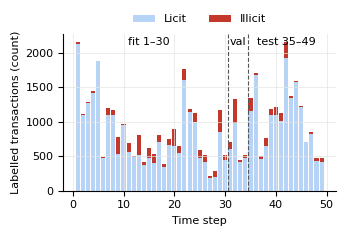

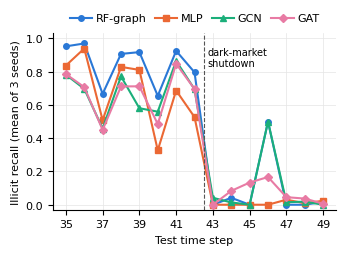

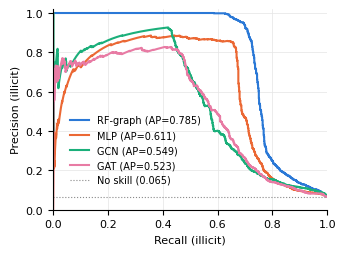

In [17]:
# Fig A
cnt = df.groupby(["time_step", "y"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(3.5, 2.4))
ax.bar(cnt.index, cnt[0], color="#b7d3f6", label="Licit", width=0.8)
ax.bar(cnt.index, cnt[1], bottom=cnt[0], color="#c4372b", label="Illicit", width=0.8)
for x in (30.5, 34.5): ax.axvline(x, color="#555", lw=0.8, ls="--")
top = ax.get_ylim()[1]
ax.text(15, top * 0.93, "fit 1–30", ha="center"); ax.text(32.5, top * 0.93, "val", ha="center")
ax.text(42, top * 0.93, "test 35–49", ha="center")
ax.set_xlabel("Time step"); ax.set_ylabel("Labelled transactions (count)")
ax.legend(frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(); fig.savefig("figs/fig_labels_per_step.pdf"); plt.show()

# Fig B
fig, ax = plt.subplots(figsize=(3.5, 2.6))
for m, (c, mk) in STYLE.items():
    ax.plot(per_step.step, per_step[m], color=c, marker=mk, ms=4, lw=1.5, label=m)
ax.axvline(42.5, color="#555", lw=0.8, ls="--"); ax.text(42.7, 0.95, "dark-market\nshutdown", va="top", fontsize=7)
ax.set_xlabel("Test time step"); ax.set_ylabel("Illicit recall (mean of 3 seeds)")
ax.set_ylim(-0.03, 1.03); ax.set_xticks(range(35, 50, 2))
ax.legend(frameon=False, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0), handletextpad=0.3, columnspacing=0.8)
fig.tight_layout(); fig.savefig("figs/fig_recall_per_step.pdf"); plt.show()

# Fig C
fig, ax = plt.subplots(figsize=(3.5, 2.6))
for m, (c, mk) in STYLE.items():
    p17 = preds[(m + " rev", 17)][0]
    pr, rc, _ = precision_recall_curve(y_test, p17)
    ax.plot(rc, pr, color=c, lw=1.5, label=f"{m} (AP={fast_ap(y_test, p17):.3f})")
ax.axhline(y_test.mean(), color="#888", lw=0.8, ls=":", label=f"No skill ({y_test.mean():.3f})")
ax.set_xlabel("Recall (illicit)"); ax.set_ylabel("Precision (illicit)"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.legend(frameon=False, fontsize=7, loc="lower left", bbox_to_anchor=(0.03, 0.08))
fig.tight_layout(); fig.savefig("figs/fig_pr_curves.pdf"); plt.show()

In [16]:
import sklearn, torch_geometric, matplotlib, platform, subprocess, os

print("CPU:", subprocess.run("lscpu | grep 'Model name'", shell=True, capture_output=True, text=True).stdout.strip())
print("RAM GB:", round(os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES') / 1e9, 1))
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| sklearn", sklearn.__version__, "| networkx", nx.__version__, "| torch", torch.__version__,
      "| PyG", torch_geometric.__version__, "| matplotlib", matplotlib.__version__)
rt = pd.Series({f"{k[0]}|{k[1]}": v for k, v in runtime.items()})
print("\nRuntime per model (s, mean over seeds):")
print(rt.groupby(lambda s: s.split("|")[0]).mean().round(1))

CPU: Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz
RAM GB: 13.6
GPU: Tesla T4
Python 3.13.16 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1 | networkx 3.7 | torch 2.14.1+cu130 | PyG 2.8.1 | matplotlib 3.10.0

Runtime per model (s, mean over seeds):
GAT              1.0
GAT rev          2.4
GCN              2.7
GCN rev          3.3
MLP rev          1.0
RF-graph        38.2
RF-graph rev    40.9
RF-local        40.7
RF-local rev    40.9
dtype: float64


In [18]:
!zip -r figs.zip figs
from google.colab import files
files.download("figs.zip")

  adding: figs/ (stored 0%)
  adding: figs/fig_pr_curves.pdf (deflated 3%)
  adding: figs/fig_recall_per_step.pdf (deflated 10%)
  adding: figs/fig_labels_per_step.pdf (deflated 9%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>